In [3]:
!nvidia-smi

Wed Sep 17 18:12:12 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 575.57.08              Driver Version: 575.57.08      CUDA Version: 12.9     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-PCIE-40GB          On  |   00000000:89:00.0 Off |                    0 |
| N/A   63C    P0            263W /  250W |   36483MiB /  40960MiB |    100%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [1]:
import numpy as np, pandas as pd, yaml
from src.dataio.dataset import load_metadata_any, build_meta_vectors
from src.dataio.dataset import CLIN_NUM, CLIN_CAT, CAT_VALS

cfg = yaml.safe_load(open("configs/default.yaml"))
sel = cfg.get("metadata_features", None)
meta_path = cfg.get("metadata_path", "data/CADICA/metadata.xlsx")

m = load_metadata_any(meta_path)
vecs = build_meta_vectors(m, selected_features=sel)
pids = sorted(vecs.keys())[:5]  # peek first 5
print("[meta] patients loaded:", len(vecs))

# reconstruct expanded order (same logic as dataset)
used_num = list(CLIN_NUM)
used_cat = list(CLIN_CAT)
if sel:
    if sel.get("numeric"):
        used_num = [k for k in sel["numeric"] if k in CLIN_NUM]
    if sel.get("categorical"):
        used_cat = [k for k in sel["categorical"] if k in CLIN_CAT]
cat_expanded = []
for k in used_cat:
    for b in CAT_VALS.get(k, ["no","yes"]):
        cat_expanded.append(f"{k}={b}")
names = used_num + cat_expanded
print("[meta] numeric:", used_num)
print("[meta] categorical:", used_cat)
print("[meta] expanded order:", names)
print("[meta] tab_dim:", len(names))

# show sample vectors and finite checks
for pid in pids:
    v = vecs[pid]
    print(f"\npatient {pid}: len={len(v)}, finite={np.isfinite(v).all()}, "
          f"min={float(np.min(v)):.3f}, max={float(np.max(v)):.3f}")
    # print first few values with names
    show = min(10, len(v))
    for i in range(show):
        print(f"  {i:02d} {names[i]:<24} {float(v[i]): .3f}")

[meta] patients loaded: 42
[meta] numeric: ['age']
[meta] categorical: ['sex']
[meta] expanded order: ['age', 'sex=female', 'sex=male']
[meta] tab_dim: 3

patient 1: len=3, finite=True, min=-1.309, max=0.000
  00 age                      -1.309
  01 sex=female                0.000
  02 sex=male                  0.000

patient 2: len=3, finite=True, min=-2.341, max=0.000
  00 age                      -2.341
  01 sex=female                0.000
  02 sex=male                  0.000

patient 3: len=3, finite=True, min=-2.341, max=0.000
  00 age                      -2.341
  01 sex=female                0.000
  02 sex=male                  0.000

patient 4: len=3, finite=True, min=-1.230, max=0.000
  00 age                      -1.230
  01 sex=female                0.000
  02 sex=male                  0.000

patient 5: len=3, finite=True, min=-0.992, max=0.000
  00 age                      -0.992
  01 sex=female                0.000
  02 sex=male                  0.000


In [1]:
import pandas as pd

df = pd.read_csv("outputs/index/all_keyframes.csv")
print(df["label"].value_counts())
print(df["label"].value_counts(normalize=True))  # percentages

label
1    4364
0    2292
Name: count, dtype: int64
label
1    0.655649
0    0.344351
Name: proportion, dtype: float64


In [2]:
import pandas as pd

for split in ["train", "val", "test"]:
    df = pd.read_csv(f"outputs/index/{split}.csv")
    counts = df["label"].value_counts().sort_index()
    print(f"\n=== {split.upper()} ===")
    print(counts)
    print("lesion %:", round(100 * counts.get(1, 0) / len(df), 2))


=== TRAIN ===
label
0    1730
1    3624
Name: count, dtype: int64
lesion %: 67.69

=== VAL ===
label
0    322
1    244
Name: count, dtype: int64
lesion %: 43.11

=== TEST ===
label
0    240
1    496
Name: count, dtype: int64
lesion %: 67.39


In [2]:
import torch
import json
import sys
from pprint import pprint

def inspect_checkpoint(ckpt_path):
    ck = torch.load(ckpt_path, map_location='cpu')
    
    print('\n=== Model Architecture ===')
    print('Backbone:', ck['cfg'].get('backbone', 'resnet50'))
    print('Fusion:', ck['cfg'].get('fusion'))
    print('Patient channels:', ck['cfg'].get('pat_channels'))
    
    print('\n=== Training Parameters ===')
    print('Optimizer:', ck['cfg'].get('optimizer'))
    print('Learning rate:', ck['cfg'].get('lr'))
    print('Batch size:', ck['cfg'].get('batch_size'))
    print('Image size:', ck['cfg'].get('img_size'))
    
    print('\n=== Metadata Configuration ===')
    print('Features used:')
    print(json.dumps(ck['cfg']['metadata_features_used'], indent=2))
    print('Tabular dimension:', ck['tab_dim'])
    
    print('\n=== Text Configuration ===')
    print('Text encoder:', ck['cfg'].get('text_encoder', 'default'))
    print('Text cache dir:', ck['cfg'].get('text_cache_dir'))
    
    print('\n=== Original Run Parameters ===')
    if 'params' in ck:
        pprint(ck['params'])



inspect_checkpoint("/cluster/home/ammaa/Downloads/meta-cadica/outputs/checkpoints/sweep_basic/0eb1024a/best.pt")

/tmp/ipykernel_1023730/909269601.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ck = torch.load(ckpt_path, map_location='cpu')



=== Model Architecture ===
Backbone: convnext_base
Fusion: late
Patient channels: 0

=== Training Parameters ===
Optimizer: rmsprop
Learning rate: 0.0003
Batch size: 64
Image size: 224

=== Metadata Configuration ===
Features used:
{
  "numeric": [
    "age",
    "height",
    "weight",
    "bmi",
    "evol_dm_years",
    "lvef_pct",
    "n_vessels",
    "max_involvement_pct"
  ],
  "categorical": [
    "sex",
    "diabetes",
    "dyslipidemia",
    "smoker",
    "hypertension",
    "kidney_failure",
    "heart_failure",
    "atrial_fib"
  ],
  "text": null
}
Tabular dimension: 24

=== Text Configuration ===
Text encoder: sentence-transformers/all-MiniLM-L6-v2
Text cache dir: outputs/text_embeds

=== Original Run Parameters ===
{'backbone': 'convnext_base',
 'fusion': 'late',
 'lr': 0.0003,
 'optimizer': 'rmsprop',
 'pat_channels': 0}


## All keyframes stats


Loaded: /cluster/home/ammaa/Downloads/meta-cadica/outputs/index/all_keyframes.csv
Shape: (6656, 5)
   patient  video  frame                                           img_path  label
0        1      1      1  data/CADICA/selectedVideos/p1/v1/input/p1_v1_0...      0
1        1      1     26  data/CADICA/selectedVideos/p1/v1/input/p1_v1_0...      0
2        1      1     27  data/CADICA/selectedVideos/p1/v1/input/p1_v1_0...      0

=== Basic ===
Rows: 6,656
Patients: 42
Videos: 382
Unique image paths: 6,655
Exact duplicate rows: 0
Duplicate img_path entries: 1

=== Missingness (count) ===
patient     0
video       0
frame       0
img_path    0
label       0
dtype: int64

=== Label distribution (frame-level) ===
       count  percent
label                
0       2292    34.44
1       4364    65.56

=== Frames per video (summary) ===
count    382.00
mean      17.42
std        7.56
min        1.00
25%       11.25
50%       17.00
75%       23.00
90%       28.00
95%       30.00
max       43.00

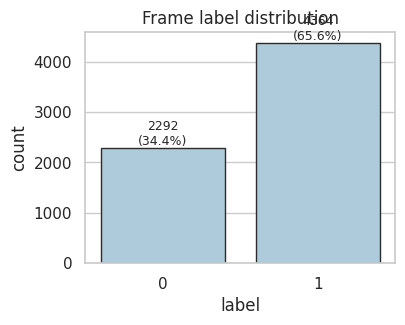

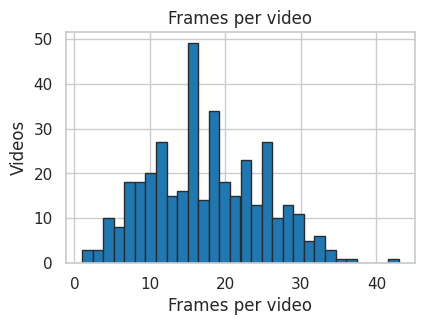

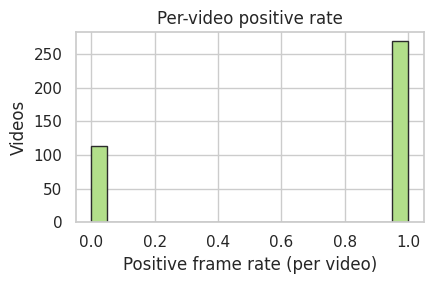


=== Example 5-fold StratifiedGroupKFold on videos (group=patient) ===
   fold  train_videos  val_videos  train_pos_rate  val_pos_rate
0     1           290          92           0.703         0.707
1     2           296          86           0.686         0.767
2     3           320          62           0.725         0.597
3     4           314          68           0.720         0.632
4     5           308          74           0.685         0.784


In [1]:
# EDA for all_keyframes.csv
# Works in a single Jupyter cell; adjust PATH_CSV if needed.

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---------- Config ----------
PATH_CSV = Path("/cluster/home/ammaa/Downloads/meta-cadica/outputs/index/all_keyframes.csv")
SAVE_FIGS = False  # set True to save plots next to the CSV
RANDOM_SEED = 42

pd.set_option("display.max_rows", 50)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

# ---------- Load ----------
df = pd.read_csv(PATH_CSV)
print("Loaded:", PATH_CSV)
print("Shape:", df.shape)
print(df.head(3))

required_cols = {"patient", "video", "frame", "img_path", "label"}
missing_cols = required_cols - set(df.columns)
assert not missing_cols, f"Missing required columns: {missing_cols}"

# Cast to expected dtypes where possible
for col in ["patient", "video", "frame", "label"]:
    if df[col].dtype.kind not in "iu":
        df[col] = pd.to_numeric(df[col], errors="coerce")
assert df[["patient", "video", "frame", "label"]].notna().all().all(), "Found NaNs after numeric casting."

# ---------- Basic stats ----------
n_rows = len(df)
n_patients = df["patient"].nunique()
n_vids = df[["patient","video"]].drop_duplicates().shape[0]
n_imgs = df["img_path"].nunique()
dup_rows = df.duplicated().sum()
dup_paths = df["img_path"].duplicated().sum()

print("\n=== Basic ===")
print(f"Rows: {n_rows:,}")
print(f"Patients: {n_patients:,}")
print(f"Videos: {n_vids:,}")
print(f"Unique image paths: {n_imgs:,}")
print(f"Exact duplicate rows: {dup_rows:,}")
print(f"Duplicate img_path entries: {dup_paths:,}")

# Missingness
print("\n=== Missingness (count) ===")
print(df.isna().sum())

# ---------- Label distribution ----------
label_counts = df["label"].value_counts().sort_index()
label_perc = (label_counts / n_rows * 100).round(2)
lab_df = pd.DataFrame({"count": label_counts, "percent": label_perc})
print("\n=== Label distribution (frame-level) ===")
print(lab_df)

# ---------- Frames per video ----------
g_vid = df.groupby(["patient","video"])
frames_per_video = g_vid.size().rename("n_frames").reset_index()
print("\n=== Frames per video (summary) ===")
print(frames_per_video["n_frames"].describe(percentiles=[.25,.5,.75,.9,.95]).round(2))

# ---------- Per-video label stats (assumes binary 0/1) ----------
# If non-binary, this will still compute rate of '1' frames where present.
per_video = g_vid["label"].agg(
    frames="size",
    pos_frames=lambda s: (s == 1).sum(),
    neg_frames=lambda s: (s == 0).sum(),
    pos_rate=lambda s: (s == 1).mean()
).reset_index()

per_video["any_positive"] = per_video["pos_frames"] > 0
print("\n=== Per-video stats (first 10) ===")
print(per_video.head(10))

print("\nVideos with any positive frames:", per_video["any_positive"].sum(), "/", len(per_video))
print("Median positive-frame rate per video:", per_video["pos_rate"].median().round(3))

# ---------- Per-patient aggregates ----------
per_patient = per_video.groupby("patient").agg(
    n_videos=("video","nunique"),
    frames=("frames","sum"),
    videos_any_pos=("any_positive","sum"),
    mean_pos_rate=("pos_rate","mean")
).reset_index().sort_values("n_videos", ascending=False)

print("\n=== Per-patient aggregates (top 10 by n_videos) ===")
print(per_patient.head(10))

# ---------- Path consistency checks ----------
# Expect pattern .../p{patient}/v{video}/input/p{patient}_v{video}_{frame:05d}.png
pat = re.compile(r"/p(?P<p>\d+)/v(?P<v>\d+)/input/p(?P<p2>\d+)_v(?P<v2>\d+)_(?P<frame>\d+)\.png$")
parts = df["img_path"].str.extract(pat)
consistent = (
    parts.notna().all(1)
    & (parts["p"].astype(int) == df["patient"])
    & (parts["v"].astype(int) == df["video"])
    & (parts["p2"].astype(int) == df["patient"])
    & (parts["v2"].astype(int) == df["video"])
    & (parts["frame"].astype(int) == df["frame"])
)
n_inconsistent = (~consistent).sum()
print("\n=== Path consistency ===")
print(f"Inconsistent rows vs columns: {n_inconsistent}")

# ---------- Plots ----------
sns.set_context("notebook")
sns.set_style("whitegrid")

figs = []

# Label distribution plot
fig1, ax1 = plt.subplots(figsize=(4,3))
order = sorted(df["label"].unique())
sns.countplot(data=df, x="label", order=order, ax=ax1, color="#A5CDE2", edgecolor="#2b2b2b")
total = len(df)
for p in ax1.patches:
    val = int(p.get_height())
    ax1.text(p.get_x()+p.get_width()/2, val, f"{val}\n({val/total*100:.1f}%)",
             ha="center", va="bottom", fontsize=9)
ax1.set_title("Frame label distribution")
figs.append(("label_dist", fig1))

# Frames per video histogram
fig2, ax2 = plt.subplots(figsize=(4.5,3))
ax2.hist(frames_per_video["n_frames"], bins=30, color="#2078B3", edgecolor="#2b2b2b")
ax2.set_xlabel("Frames per video")
ax2.set_ylabel("Videos")
ax2.set_title("Frames per video")
figs.append(("frames_per_video_hist", fig2))

# Positive rate per video histogram (if binary labels)
if df["label"].dropna().isin([0,1]).all():
    fig3, ax3 = plt.subplots(figsize=(4.5,3))
    ax3.hist(per_video["pos_rate"], bins=20, color="#B2DF8A", edgecolor="#2b2b2b")
    ax3.set_xlabel("Positive frame rate (per video)")
    ax3.set_ylabel("Videos")
    ax3.set_title("Per-video positive rate")
    figs.append(("pos_rate_per_video_hist", fig3))

plt.tight_layout()
plt.show()

# ---------- Optional: save figures ----------
if SAVE_FIGS:
    out_dir = PATH_CSV.parent / "eda_figs"
    out_dir.mkdir(exist_ok=True, parents=True)
    for name, fig in figs:
        fig.savefig(out_dir / f"{name}.png", dpi=160, bbox_inches="tight")
    print(f"Saved {len(figs)} figure(s) to:", out_dir)

# ---------- Optional: stratified split by patient (if sklearn available) ----------
try:
    from sklearn.model_selection import StratifiedGroupKFold
    # Use per-video target = any_positive (avoid frame-level leakage)
    X = per_video[["patient","video"]].copy()
    y = per_video["any_positive"].astype(int).values
    groups = per_video["patient"].values

    sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
    splits = []
    for i, (tr, va) in enumerate(sgkf.split(X, y, groups), 1):
        tr_videos = len(tr); va_videos = len(va)
        tr_pos = y[tr].mean(); va_pos = y[va].mean()
        splits.append((i, tr_videos, va_videos, tr_pos, va_pos))
    split_df = pd.DataFrame(splits, columns=["fold","train_videos","val_videos","train_pos_rate","val_pos_rate"])
    print("\n=== Example 5-fold StratifiedGroupKFold on videos (group=patient) ===")
    print(split_df.round(3))
except Exception as e:
    print("\n[Optional split] sklearn not available or error:", e)


In [2]:
# Stats for CV folds: outer train, inner train/val, outer val, and pristine test
# Adjust paths if needed.

from pathlib import Path
import re
import numpy as np
import pandas as pd

# ---------- Paths / knobs ----------
FOLDS_ROOT = Path("/cluster/home/ammaa/Downloads/meta-cadica/outputs/folds/patient_stratified_5fold")
TEST_CSV   = Path("/cluster/home/ammaa/Downloads/meta-cadica/outputs/index/test_pristine.csv")
INNER_VAL_FRAC = 0.20  # matches default in 02_train_kfold.py
SEED = 1337            # matches configs/default.yaml or CLI fallback
RNG = np.random.RandomState(SEED)

# ---------- Helpers ----------
def _validate_schema(df: pd.DataFrame):
    need = {"patient","video","frame","img_path","label"}
    miss = need - set(df.columns)
    if miss:
        raise ValueError(f"CSV missing columns: {miss}")
    # enforce numeric for key cols
    for c in ["patient","video","frame","label"]:
        df[c] = pd.to_numeric(df[c], errors="coerce").astype(int)
    return df

def _basic_stats(df: pd.DataFrame, name: str):
    n_rows = len(df)
    n_pats = df["patient"].nunique()
    n_vids = df[["patient","video"]].drop_duplicates().shape[0]
    n_paths = df["img_path"].nunique()
    dup_rows = int(df.duplicated().sum())
    dup_paths = int(df["img_path"].duplicated().sum())

    # labels
    lab_counts = df["label"].value_counts().sort_index()
    lab_perc = (lab_counts / max(n_rows,1) * 100).round(2)
    labs = {f"label_{int(k)}_n": int(v) for k,v in lab_counts.items()}
    labs.update({f"label_{int(k)}_pct": float(lab_perc.loc[k]) for k in lab_perc.index})

    # frames per video
    frames_per_video = df.groupby(["patient","video"]).size().rename("n_frames").reset_index()
    fpv_desc = frames_per_video["n_frames"].describe(percentiles=[.25,.5,.75,.9,.95]).to_dict()

    # per-video positive rate (works if labels are 0/1; otherwise mean of ==1)
    pv = df.groupby(["patient","video"])["label"].agg(
        frames="size",
        pos_frames=lambda s: (s == 1).sum(),
    ).reset_index()
    pv["pos_rate"] = pv["pos_frames"] / pv["frames"]
    pv_desc = pv["pos_rate"].describe(percentiles=[.25,.5,.75,.9,.95]).to_dict()
    any_pos_videos = int((pv["pos_frames"] > 0).sum())

    row = {
        "split": name,
        "rows": n_rows,
        "patients": n_pats,
        "videos": n_vids,
        "unique_img_paths": n_paths,
        "dup_rows": dup_rows,
        "dup_img_paths": dup_paths,
        "videos_any_positive": any_pos_videos,
        "fpv_mean": float(fpv_desc.get("mean", float("nan"))),
        "fpv_median": float(fpv_desc.get("50%", float("nan"))),
        "fpv_min": float(fpv_desc.get("min", float("nan"))),
        "fpv_max": float(fpv_desc.get("max", float("nan"))),
        "pos_rate_mean": float(pv_desc.get("mean", float("nan"))),
        "pos_rate_median": float(pv_desc.get("50%", float("nan"))),
        "pos_rate_min": float(pv_desc.get("min", float("nan"))),
        "pos_rate_max": float(pv_desc.get("max", float("nan"))),
    }
    row.update(labs)
    return row

def _inner_split_like_training(train_df: pd.DataFrame, inner_val_frac=INNER_VAL_FRAC, seed=SEED):
    # Reproduce 02_train_kfold.py: stratify by patient-level label if both classes exist
    from sklearn.model_selection import GroupShuffleSplit, StratifiedShuffleSplit

    # patient-level label = max(label) across their frames
    pl = train_df.groupby("patient")["label"].max().reset_index().rename(columns={"label":"patient_label"})
    y_p = pl["patient_label"].astype(int).values
    pat_ids = pl["patient"].astype(int).values

    if len(np.unique(y_p)) >= 2:
        sss = StratifiedShuffleSplit(n_splits=1, test_size=inner_val_frac, random_state=seed)
        tr_pidx, va_pidx = next(sss.split(np.zeros(len(pl)), y_p))
        tr_pats = set(pat_ids[tr_pidx].tolist())
        va_pats = set(pat_ids[va_pidx].tolist())
    else:
        gss = GroupShuffleSplit(n_splits=1, test_size=inner_val_frac, random_state=seed)
        tr_idx_tmp, va_idx_tmp = next(gss.split(train_df, groups=train_df["patient"]))
        tr_pats = set(train_df.iloc[tr_idx_tmp]["patient"].unique().tolist())
        va_pats = set(train_df.iloc[va_idx_tmp]["patient"].unique().tolist())

    inner_tr = train_df[train_df["patient"].isin(tr_pats)].copy()
    inner_va = train_df[train_df["patient"].isin(va_pats)].copy()

    # Sanity: no patient overlap
    assert set(inner_tr["patient"]).isdisjoint(set(inner_va["patient"])), "Inner split patient leakage."
    return inner_tr.reset_index(drop=True), inner_va.reset_index(drop=True)

def _leakage_ok(a: pd.DataFrame, b: pd.DataFrame):
    pats_a = set(a["patient"].unique().tolist())
    pats_b = set(b["patient"].unique().tolist())
    return pats_a.isdisjoint(pats_b)

# ---------- Iterate folds ----------
fold_dirs = sorted([p for p in FOLDS_ROOT.iterdir() if p.is_dir() and p.name.startswith("fold_")],
                   key=lambda p: int(p.name.split("_")[-1]))

all_rows = []

for fold in fold_dirs:
    tr = pd.read_csv(fold / "train.csv")
    va = pd.read_csv(fold / "val.csv")
    tr = _validate_schema(tr)
    va = _validate_schema(va)

    # Inner split from outer-train (patient-stratified)
    inner_tr, inner_va = _inner_split_like_training(tr, INNER_VAL_FRAC, SEED)

    # Quick leakage assertions
    assert _leakage_ok(tr, va), f"Outer leakage in {fold.name}"
    assert _leakage_ok(inner_tr, inner_va), f"Inner leakage in {fold.name}"

    # Collect stats rows
    all_rows.append(_basic_stats(tr, f"{fold.name}:train"))
    all_rows.append(_basic_stats(inner_tr, f"{fold.name}:inner_train"))
    all_rows.append(_basic_stats(inner_va, f"{fold.name}:inner_val"))
    all_rows.append(_basic_stats(va, f"{fold.name}:val"))

# Pristine test
if TEST_CSV.exists():
    te = pd.read_csv(TEST_CSV)
    te = _validate_schema(te)
    all_rows.append(_basic_stats(te, "test_pristine"))
else:
    print(f"[warn] test csv not found: {TEST_CSV}")

stats_df = pd.DataFrame(all_rows)

# ---------- Display ----------
# Ordered columns for readability
col_order = [
    "split","rows","patients","videos","unique_img_paths","dup_rows","dup_img_paths",
    "label_0_n","label_0_pct","label_1_n","label_1_pct",
    "videos_any_positive","fpv_min","fpv_median","fpv_mean","fpv_max",
    "pos_rate_min","pos_rate_median","pos_rate_mean","pos_rate_max",
]
for c in col_order:
    if c not in stats_df.columns:
        stats_df[c] = np.nan

display(stats_df[col_order].fillna(""))

# Summary across folds (outer train/val and inner sets)
def _agg_view(prefix):
    sub = stats_df[stats_df["split"].str.contains(prefix)]
    if sub.empty:
        return None
    view = sub.assign(split=sub["split"].str.extract(r"(fold_\\d+):(.*)$")[1])
    grp = view.groupby("split", as_index=False).agg({
        "rows":"sum","patients":"sum","videos":"sum",
        "label_0_n":"sum","label_1_n":"sum"
    })
    # mean per-fold for quick glance
    per_fold = sub.copy()
    per_fold["fold"] = per_fold["split"].str.extract(r"fold_(\\d+)")
    per_fold = per_fold.groupby("fold").agg({
        "rows":"sum","patients":"sum","videos":"sum",
        "label_0_n":"sum","label_1_n":"sum",
        "fpv_mean":"mean","pos_rate_mean":"mean"
    }).rename_axis("fold").reset_index()
    return grp, per_fold

for part in ["train","inner_train","inner_val","val"]:
    res = _agg_view(part)
    if res is None:
        continue
    grp, per_fold = res
    print(f"\n=== Totals across all folds ({part}) ===")
    display(grp)
    print(f"Mean per-fold ({part})")
    display(per_fold.describe().round(2))

# Patient leakage checks: outer train vs val per fold; test vs each fold's val
if TEST_CSV.exists():
    te_pats = set(te["patient"].unique().tolist())
print("\n=== Leakage checks ===")
for fold in fold_dirs:
    tr = pd.read_csv(fold / "train.csv")
    va = pd.read_csv(fold / "val.csv")
    tr = _validate_schema(tr); va = _validate_schema(va)
    ok_outer = _leakage_ok(tr, va)
    msg = f"{fold.name}: outer_train vs val leakage: {'NO' if ok_outer else 'YES'}"
    if TEST_CSV.exists():
        ok_test_val = set(va["patient"]).isdisjoint(te_pats)
        msg += f" | val vs test_pristine leakage: {'NO' if ok_test_val else 'YES'}"
    print(msg)


,split,rows,patients,videos,unique_img_paths,dup_rows,dup_img_paths,label_0_n,label_0_pct,label_1_n,label_1_pct,videos_any_positive,fpv_min,fpv_median,fpv_mean,fpv_max,pos_rate_min,pos_rate_median,pos_rate_mean,pos_rate_max
0,fold_0:train,4728,30,279,4727,0,1,1344,28.43,3384,71.57,210,1.0,16.0,16.946237,43.0,0.0,1.0,0.752688,1.0
1,fold_0:inner_train,3748,24,230,3747,0,1,809,21.58,2939,78.42,185,1.0,16.0,16.295652,35.0,0.0,1.0,0.804348,1.0
2,fold_0:inner_val,980,6,49,980,0,0,535,54.59,445,45.41,25,4.0,19.0,20.000000,43.0,0.0,1.0,0.510204,1.0
3,fold_0:val,1173,8,64,1173,0,0,567,48.34,606,51.66,36,4.0,17.0,18.328125,34.0,0.0,1.0,0.562500,1.0
4,fold_1:train,4450,30,263,4450,0,0,1461,32.83,2989,67.17,188,1.0,16.0,16.920152,43.0,0.0,1.0,0.714829,1.0
5,fold_1:inner_train,3516,24,218,3516,0,0,1039,29.55,2477,70.45,161,1.0,15.0,16.128440,34.0,0.0,1.0,0.738532,1.0
6,fold_1:inner_val,934,6,45,934,0,0,422,45.18,512,54.82,27,5.0,19.0,20.755556,43.0,0.0,1.0,0.600000,1.0
7,fold_1:val,1451,8,80,1450,0,1,450,31.01,1001,68.99,58,2.0,18.0,18.137500,35.0,0.0,1.0,0.725000,1.0
8,fold_2:train,4782,30,284,4781,0,1,1549,32.39,3233,67.61,201,1.0,16.0,16.838028,35.0,0.0,1.0,0.707746,1.0
9,fold_2:inner_train,3776,24,228,3775,0,1,1087,28.79,2689,71.21,168,1.0,16.0,16.561404,35.0,0.0,1.0,0.736842,1.0



=== Totals across all folds (train) ===


,split,rows,patients,videos,label_0_n,label_1_n


Mean per-fold (train)


,rows,patients,videos,label_0_n,label_1_n,fpv_mean,pos_rate_mean
count,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,NaN,NaN,NaN,NaN,NaN,NaN,NaN


...


=== Totals across all folds (val) ===


,split,rows,patients,videos,label_0_n,label_1_n


Mean per-fold (val)


,rows,patients,videos,label_0_n,label_1_n,fpv_mean,pos_rate_mean
count,0.0,0.0,0.0,0.0,0.0,0.0,0.0
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN
max,NaN,NaN,NaN,NaN,NaN,NaN,NaN



=== Leakage checks ===
fold_0: outer_train vs val leakage: NO | val vs test_pristine leakage: NO
fold_1: outer_train vs val leakage: NO | val vs test_pristine leakage: NO
fold_2: outer_train vs val leakage: NO | val vs test_pristine leakage: NO
fold_3: outer_train vs val leakage: NO | val vs test_pristine leakage: NO
fold_4: outer_train vs val leakage: NO | val vs test_pristine leakage: NO


In [3]:
# Metadata profiling for CADICA (numerical, categorical, text)
# - Uses groups from configs/default.yaml
# - Reads: data/CADICA/metadata.xlsx

from pathlib import Path
import numpy as np
import pandas as pd
import yaml
import re

# ---------- Paths ----------
ROOT = Path("/cluster/home/ammaa/Downloads/meta-cadica")
CFG_PATH = ROOT / "configs" / "default.yaml"
META_XLSX = None  # set from cfg below

# ---------- Load config ----------
cfg = yaml.safe_load(open(CFG_PATH))
feat = (cfg.get("metadata_features") or {})
num_cols_cfg = (feat.get("numeric") or [])[:]
cat_cols_cfg = (feat.get("categorical") or [])[:]
text_cols_cfg = (feat.get("text") or [])[:]
META_XLSX = ROOT / cfg.get("metadata_path", "data/CADICA/metadata.xlsx")

print("Config numeric:", num_cols_cfg)
print("Config categorical:", cat_cols_cfg)
print("Config text:", text_cols_cfg)
print("Excel path:", META_XLSX)

# ---------- Load Excel ----------
df = pd.read_excel(META_XLSX)  # engine auto-detected (openpyxl preferred)
print("Metadata shape:", df.shape)
print("Columns:", list(df.columns))

# Keep only columns that actually exist (robust to naming changes)
def exists(cols): 
    return [c for c in cols if c in df.columns]

num_cols = exists(num_cols_cfg)
cat_cols = exists(cat_cols_cfg)
text_cols = exists(text_cols_cfg)

# Fallback: If any list is empty, infer columns by dtype/heuristics (non-destructive)
if not num_cols:
    num_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c])]
if not cat_cols:
    # low-cardinality non-numeric treated as categorical
    cat_cols = [c for c in df.columns 
                if c not in num_cols 
                and df[c].dtype == object 
                and df[c].nunique(dropna=True) <= max(20, int(len(df)*0.05))]
if not text_cols:
    # higher-cardinality object columns as text
    text_cols = [c for c in df.columns if c not in num_cols + cat_cols and df[c].dtype == object]

print("\nUsing columns")
print(" numerical:", num_cols)
print(" categorical:", cat_cols)
print(" text:", text_cols)

# ---------- Numerical stats ----------
num_stats_rows = []
for c in num_cols:
    s = pd.to_numeric(df[c], errors="coerce")
    desc = s.describe(percentiles=[.25,.5,.75])
    num_stats_rows.append({
        "column": c,
        "count": int(desc.get("count", 0)),
        "missing": int(s.isna().sum()),
        "unique": int(s.nunique(dropna=True)),
        "mean": float(desc.get("mean", np.nan)),
        "std": float(desc.get("std", np.nan)),
        "min": float(desc.get("min", np.nan)),
        "p25": float(desc.get("25%", np.nan)),
        "p50": float(desc.get("50%", np.nan)),
        "p75": float(desc.get("75%", np.nan)),
        "max": float(desc.get("max", np.nan)),
    })
num_stats = pd.DataFrame(num_stats_rows).sort_values("column") if num_stats_rows else pd.DataFrame()
display(num_stats)

# ---------- Categorical stats ----------
def vc_table(series, topn=20):
    vc = series.value_counts(dropna=False)
    # Show NaN explicitly as "<NA>"
    idx = [("<NA>" if (isinstance(i, float) and pd.isna(i)) or (pd.isna(i)) else str(i)) for i in vc.index]
    out = pd.DataFrame({"category": idx, "count": vc.values})
    out["percent"] = (out["count"] / len(series) * 100).round(2)
    return out.head(topn)

cat_summaries = []
cat_tables = {}
for c in cat_cols:
    s = df[c]
    cat_summaries.append({
        "column": c,
        "cardinality": int(s.nunique(dropna=True)),
        "missing": int(s.isna().sum()),
        "non_missing": int(s.notna().sum())
    })
    cat_tables[c] = vc_table(s, topn=20)
cat_summary = pd.DataFrame(cat_summaries).sort_values("column") if cat_summaries else pd.DataFrame()
display(cat_summary)
# Display each categorical top-20 table
for c in cat_cols:
    print(f"\nTop categories for: {c}")
    display(cat_tables[c])

# ---------- Text stats and examples ----------
def text_len_stats(s):
    s = s.fillna("").astype(str).str.strip()
    non_empty = s[s.str.len() > 0]
    lengths = non_empty.str.len()
    words = non_empty.str.split().map(len)
    out = {
        "non_empty": int(non_empty.shape[0]),
        "missing": int((s == "").sum()),
        "avg_chars": float(lengths.mean() if not lengths.empty else np.nan),
        "avg_words": float(words.mean() if not words.empty else np.nan),
    }
    # sample up to 5 examples
    ex = non_empty.sample(n=min(5, len(non_empty)), random_state=1337).tolist() if len(non_empty) else []
    return out, ex

text_rows = []
text_examples = {}
for c in text_cols:
    stats, ex = text_len_stats(df[c])
    row = {"column": c, **stats}
    text_rows.append(row)
    text_examples[c] = ex
text_summary = pd.DataFrame(text_rows).sort_values("column") if text_rows else pd.DataFrame()
display(text_summary)
for c in text_cols:
    print(f"\nExamples for text column: {c}")
    for i, t in enumerate(text_examples[c], 1):
        # Compact single-line preview
        t1 = re.sub(r"\\s+", " ", str(t)).strip()
        print(f"  {i}. {t1[:180]}{'…' if len(t1) > 180 else ''}")

# ---------- Optional: save summaries next to Excel ----------
SAVE = False
if SAVE:
    out_dir = META_XLSX.parent / "metadata_stats"
    out_dir.mkdir(exist_ok=True, parents=True)
    if not num_stats.empty: num_stats.to_csv(out_dir / "numerical_stats.csv", index=False)
    if not cat_summary.empty: cat_summary.to_csv(out_dir / "categorical_summary.csv", index=False)
    if text_rows: text_summary.to_csv(out_dir / "text_summary.csv", index=False)
    print("Saved CSVs to:", out_dir)


Config numeric: ['age', 'height', 'weight', 'bmi', 'evol_dm_years', 'lvef_pct', 'n_vessels', 'max_involvement_pct']
Config categorical: ['sex', 'diabetes', 'dyslipidemia', 'smoker', 'hypertension', 'kidney_failure', 'heart_failure', 'atrial_fib']
Config text: ['another_comorb', 'indication', 'later_events']
Excel path: /cluster/home/ammaa/Downloads/meta-cadica/data/CADICA/metadata.xlsx
Metadata shape: (42, 20)
Columns: ['Patient ID', 'Age (years)', 'Sex', 'Height (m)', 'Weight (kg)', 'BMI', 'Diabetes mellitus', 'Evolution diabetes (years)', 'Dyslipidemia', 'Smoker', 'High blood pressure', 'Another comorbidity', 'Kidney failure', 'Heart failure', 'Atrial fibrillation', 'Left ventricular ejection fraction', 'Clinical indication for angiogrphy', 'Number of vessels affected', 'Maximum degree of the coronary artery involvement', 'Later medical events']

Using columns
 numerical: ['Patient ID', 'Age (years)', 'Height (m)', 'Weight (kg)', 'BMI', 'Diabetes mellitus', 'Evolution diabetes (years

,column,count,missing,unique,mean,std,min,p25,p50,p75,max
1,Age (years),42,0,27,68.785714,12.667484,42.000000,59.250000,71.500000,78.000000,89.000000
12,Atrial fibrillation,42,0,2,0.047619,0.215540,0.000000,0.000000,0.000000,0.000000,1.000000
4,BMI,20,22,20,32.187288,7.423334,24.977043,27.694673,30.294616,34.711461,56.923596
5,Diabetes mellitus,42,0,2,0.404762,0.496796,0.000000,0.000000,0.000000,1.000000,1.000000
7,Dyslipidemia,42,0,2,0.404762,0.496796,0.000000,0.000000,0.000000,1.000000,1.000000
6,Evolution diabetes (years),41,1,12,3.146341,5.294152,0.000000,0.000000,0.000000,6.000000,23.000000
11,Heart failure,42,0,2,0.142857,0.354169,0.000000,0.000000,0.000000,0.000000,1.000000
2,Height (m),20,22,14,1.636500,0.079821,1.520000,1.585000,1.645000,1.660000,1.830000
9,High blood pressure,42,0,2,0.619048,0.491507,0.000000,0.000000,1.000000,1.000000,1.000000
10,Kidney failure,42,0,2,0.142857,0.354169,0.000000,0.000000,0.000000,0.000000,1.000000


,column,cardinality,missing,non_missing
1,Another comorbidity,19,0,42
3,Clinical indication for angiogrphy,6,1,41
5,Later medical events,8,0,42
2,Left ventricular ejection fraction,5,1,41
4,Maximum degree of the coronary artery involvement,5,0,42
0,Sex,2,0,42



Top categories for: Sex


,category,count,percent
0,M,22,52.38
1,F,20,47.62


...


Top categories for: Maximum degree of the coronary artery involvement


,category,count,percent
0,>70%,15,35.71
1,> 70%,13,30.95
2,20-50%,8,19.05
3,<20%,5,11.90
4,< 20%,1,2.38



Top categories for: Later medical events


,category,count,percent
0,0,30,71.43
1,non-cardiac death,5,11.90
2,cardiac death,2,4.76
3,myocardial infarction,1,2.38
4,covid pneumonia,1,2.38
5,community-acquired pneumonia,1,2.38
6,acute descompensated heart failure,1,2.38
7,"acute descompensated heart failure, de novo at...",1,2.38


""


In [5]:
# Percent table for Sex and binary comorbidities (two-decimal percentages)
# File: /cluster/home/ammaa/Downloads/meta-cadica/data/CADICA/metadata.xlsx

from pathlib import Path
import numpy as np
import pandas as pd
import re

# --- Settings ---
DEC = 2  # number of decimals for percents
pd.set_option("display.float_format", lambda x: f"{x:.{DEC}f}")

PATH = Path("/cluster/home/ammaa/Downloads/meta-cadica/data/CADICA/metadata.xlsx")
df = pd.read_excel(PATH)

# -------- Robust column resolver --------
def norm_key(s: str) -> str:
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

col_map = {norm_key(c): c for c in df.columns}

def resolve(first_label: str, synonyms: list[str], required=False) -> str | None:
    for key in [first_label, *synonyms]:
        k = norm_key(key)
        if k in col_map:
            return col_map[k]
    if required:
        raise KeyError(f"Required column not found for: {first_label} (tried: { [first_label, *synonyms] })\nAvailable: {list(df.columns)}")
    return None

WANTS = [
    ("Sex", ["gender", "biologicalsex", "patientsex"]),
    ("Diabetes mellitus", ["diabetes mellitus", "diabetes", "dm", "diabetesmellitus"]),  # required
    ("Dyslipidemia", ["dyslipidemia", "hyperlipidemia"]),
    ("Smoker", ["smoker", "smoking", "tobacco", "cigarette"]),
    ("High blood pressure (Hypertension)", ["hypertension", "high blood pressure", "hbp", "htn"]),
    ("Kidney failure", ["kidney failure", "renal failure", "ckd", "chronic kidney disease"]),
    ("Heart failure", ["heart failure", "hf", "chf"]),
    ("Atrial fibrillation", ["atrial fibrillation", "af", "afib"]),
]

resolved = {}
for label, syns in WANTS:
    required = (label == "Diabetes mellitus")
    resolved[label] = resolve(label, syns, required=required)

# -------- Normalizers --------
YES = {"yes","y","true","t","1","si","sí","oui","positive","positif"}
NO  = {"no","n","false","f","0","non","negative","negatif"}

MALE = {"male","m","man","hombre","masculino","1"}
FEMALE = {"female","f","woman","mujer","femenino","0"}

def to_lower_str(v):
    if pd.isna(v):
        return None
    s = str(v).strip()
    return s.lower()

def normalize_yes_no(s: pd.Series):
    x = s.map(to_lower_str)
    out = []
    for v in x:
        if v is None or v == "" or v == "nan":
            out.append(np.nan)
        elif v in YES:
            out.append("Yes")
        elif v in NO:
            out.append("No")
        else:
            out.append(v.title())
    return pd.Series(out, index=s.index)

def normalize_sex(s: pd.Series):
    x = s.map(to_lower_str)
    out = []
    for v in x:
        if v is None or v == "" or v == "nan":
            out.append(np.nan)
        elif v in MALE:
            out.append("Male")
        elif v in FEMALE:
            out.append("Female")
        else:
            out.append(v.title())
    return pd.Series(out, index=s.index)

def pct(n, d):
    return 100.0 * n / d if d else 0.0

# -------- Compute rows (two-decimal rounding) --------
rows = []
latex_lines = []

# Sex (Male / Female)
col = resolved.get("Sex")
if col:
    sx = normalize_sex(df[col])
    denom = sx.notna().sum()
    male = int((sx == "Male").sum())
    female = int((sx == "Female").sum())
    other = int((sx.notna() & ~sx.isin(["Male","Female"])).sum())
    rows.append({
        "Variable":"Sex",
        "A_label":"Male", "A_n":male, "A_pct": round(pct(male, denom), DEC),
        "B_label":"Female", "B_n":female, "B_pct": round(pct(female, denom), DEC),
        "Missing": int(sx.isna().sum()), "Other": other
    })
    latex_lines.append(f"Sex & {pct(male, denom):.{DEC}f}\\% / {pct(female, denom):.{DEC}f}\\% \\\\")
else:
    print("[warn] Sex column not found; skipping.")

# Binary Yes/No vars (Yes / No)
for label, _ in WANTS:
    if label == "Sex":
        continue
    col = resolved.get(label)
    if not col:
        print(f"[warn] Missing column for {label}; skipping.")
        continue
    bn = normalize_yes_no(df[col])
    denom = bn.notna().sum()
    yes = int((bn == "Yes").sum())
    no  = int((bn == "No").sum())
    other = int((bn.notna() & ~bn.isin(["Yes","No"])).sum())
    rows.append({
        "Variable": label,
        "A_label":"Yes", "A_n":yes, "A_pct": round(pct(yes, denom), DEC),
        "B_label":"No",  "B_n":no,  "B_pct": round(pct(no, denom), DEC),
        "Missing": int(bn.isna().sum()), "Other": other
    })
    latex_lines.append(f"{label} & {pct(yes, denom):.{DEC}f}\\% / {pct(no, denom):.{DEC}f}\\% \\\\")

out = pd.DataFrame(rows, columns=["Variable","A_label","A_n","A_pct","B_label","B_n","B_pct","Missing","Other"])

print("Counts and percents (A / B) — percentages with two decimals:")
display(out)

print("\nLaTeX rows (two decimals):")
for ln in latex_lines:
    print(ln)


Counts and percents (A / B) — percentages with two decimals:


,Variable,A_label,A_n,A_pct,B_label,B_n,B_pct,Missing,Other
0,Sex,Male,22,52.38,Female,20,47.62,0,0
1,Diabetes mellitus,Yes,17,40.48,No,25,59.52,0,0
2,Dyslipidemia,Yes,17,40.48,No,25,59.52,0,0
3,Smoker,Yes,19,45.24,No,23,54.76,0,0
4,High blood pressure (Hypertension),Yes,26,61.90,No,16,38.10,0,0
5,Kidney failure,Yes,6,14.29,No,36,85.71,0,0
6,Heart failure,Yes,6,14.29,No,36,85.71,0,0
7,Atrial fibrillation,Yes,2,4.76,No,40,95.24,0,0



LaTeX rows (two decimals):
Sex & 52.38\% / 47.62\% \\
Diabetes mellitus & 40.48\% / 59.52\% \\
Dyslipidemia & 40.48\% / 59.52\% \\
Smoker & 45.24\% / 54.76\% \\
High blood pressure (Hypertension) & 61.90\% / 38.10\% \\
Kidney failure & 14.29\% / 85.71\% \\
Heart failure & 14.29\% / 85.71\% \\
Atrial fibrillation & 4.76\% / 95.24\% \\


In [7]:
import os, json, glob, numpy as np, pandas as pd

ROOT = "/cluster/home/ammaa/Downloads/meta-cadica/outputs/temporal_vit_all"  # change if needed

def load_fold_rows(root: str) -> pd.DataFrame:
    rows = []
    for variant in sorted([d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d))]):
        vdir = os.path.join(root, variant)
        for fusion in sorted([d for d in os.listdir(vdir) if os.path.isdir(os.path.join(vdir, d))]):
            fdir = os.path.join(vdir, fusion)
            for fjson in sorted(glob.glob(os.path.join(fdir, "fold_*", "fold_summary.json"))):
                try:
                    with open(fjson, "r") as f:
                        row = json.load(f)
                except Exception as e:
                    print(f"[warn] failed {fjson}: {e}")
                    continue
                row["variant"] = row.get("variant", variant)
                row["fusion"]  = row.get("fusion", fusion)
                # fold index fallback from path if missing
                if "fold" not in row:
                    try:
                        row["fold"] = int(os.path.basename(os.path.dirname(fjson)).split("_")[-1])
                    except Exception:
                        pass
                rows.append(row)
    return pd.DataFrame(rows)

def summarize_group(df: pd.DataFrame) -> pd.DataFrame:
    # keep only numeric val_* columns
    val_cols = [c for c in df.columns if c.startswith("val_")]
    sdf = pd.DataFrame(index=val_cols, columns=["mean","std","min","max"])
    for c in val_cols:
        v = pd.to_numeric(df[c], errors="coerce").dropna()
        if len(v):
            sdf.loc[c,"mean"] = float(v.mean())
            sdf.loc[c,"std"]  = float(v.std())
            sdf.loc[c,"min"]  = float(v.min())
            sdf.loc[c,"max"]  = float(v.max())
    return sdf

def fmt_stats(sdf: pd.DataFrame) -> str:
    lines = []
    for c in sdf.index:
        try:
            mu, sd, mn, mx = sdf.loc[c, ["mean","std","min","max"]].astype(float)
            lines.append(f"{c}: {mu:.4f} ± {sd:.4f} (min={mn:.4f}, max={mx:.4f})")
        except Exception:
            pass
    return "\n".join(lines)

# Load
df = load_fold_rows(ROOT)
if df.empty:
    raise RuntimeError(f"No fold_summary.json found under {ROOT}")

# Optional: inspect what’s available
display(df.head())

# Per-variant + fusion summaries (printed)
for variant in sorted(df["variant"].unique()):
    print(f"\n=== Variant: {variant} ===")
    subv = df[df["variant"] == variant]
    for fusion in sorted(subv["fusion"].unique()):
        subf = subv[subv["fusion"] == fusion]
        sdf = summarize_group(subf)
        print(f"\nFusion: {fusion}")
        print(fmt_stats(sdf))
        # Extras (mean best epoch/time; GPU info if present)
        if "best_epoch" in subf.columns:
            be = pd.to_numeric(subf["best_epoch"], errors="coerce").dropna()
            if len(be): print(f"Avg best_epoch: {float(be.mean()):.2f}")
        if "train_seconds" in subf.columns:
            ts = pd.to_numeric(subf["train_seconds"], errors="coerce").dropna()
            if len(ts): print(f"Avg train time (s): {float(ts.mean()):.1f}")
        if "cuda_mem_alloc_peak_mb" in subf.columns:
            ca = pd.to_numeric(subf["cuda_mem_alloc_peak_mb"], errors="coerce").dropna()
            cr = pd.to_numeric(subf.get("cuda_mem_reserved_peak_mb", pd.Series([])), errors="coerce").dropna()
            if len(ca): print(f"GPU peak alloc (MB): {float(ca.mean()):.1f}")
            if len(cr): print(f"GPU peak reserved (MB): {float(cr.mean()):.1f}")

# Global rollup across all variants/fusions (as a table)
global_stats = []
for col in sorted([c for c in df.columns if c.startswith("val_")]):
    v = pd.to_numeric(df[col], errors="coerce").dropna()
    if len(v):
        global_stats.append({
            "metric": col,
            "mean": float(v.mean()),
            "std":  float(v.std()),
            "min":  float(v.min()),
            "max":  float(v.max()),
            "n":    int(len(v)),
        })
global_summary_df = pd.DataFrame(global_stats).set_index("metric")
display(global_summary_df)

# Optional: pivot table (mean per variant/fusion for a chosen metric)
metric_of_interest = "val_bal_acc"  # change as needed
if metric_of_interest in df.columns:
    pivot_mean = df.pivot_table(index="variant", columns="fusion",
                                values=metric_of_interest, aggfunc="mean")
    display(pivot_mean.style.format("{:.4f}"))
else:
    print(f"[info] {metric_of_interest} not found in columns.")


,variant,fusion,fold,val_auc,convergence_epoch,best_epoch,train_seconds,select_metric,threshold_metric,thr_video,device,gpu_name,cuda_mem_alloc_peak_mb,cuda_mem_reserved_peak_mb,val_bal_acc,val_acc,val_recall,val_precision,val_f1,val_ap,val_fpr,val_fnr,val_kappa
0,cls_cross,early,0,0.62,1,1,469.64,bal_acc,bal_acc,0.86,cuda,NVIDIA A100-PCIE-40GB,20105.28,22096.00,0.50,0.56,1.00,0.56,0.72,0.70,1.00,0.00,0.00
1,cls_cross,early,1,0.32,1,1,443.90,bal_acc,bal_acc,0.77,cuda,NVIDIA A100-PCIE-40GB,20106.13,22096.00,0.50,0.28,0.00,0.00,0.00,0.63,0.00,1.00,0.00
2,cls_cross,early,2,0.60,1,1,469.07,bal_acc,bal_acc,0.96,cuda,NVIDIA A100-PCIE-40GB,20104.42,22096.00,0.50,0.24,0.00,0.00,0.00,0.86,0.00,1.00,0.00
3,cls_cross,early,3,0.58,14,14,708.17,bal_acc,bal_acc,0.01,cuda,NVIDIA A100-PCIE-40GB,20104.34,22096.00,0.50,0.78,1.00,0.78,0.88,0.84,1.00,0.00,0.00
4,cls_cross,early,4,0.37,1,1,447.54,bal_acc,bal_acc,0.82,cuda,NVIDIA A100-PCIE-40GB,20105.14,22096.00,0.38,0.31,0.24,0.60,0.34,0.70,0.47,0.76,-0.15



=== Variant: cls_cross ===

Fusion: early
val_auc: 0.4980 ± 0.1418 (min=0.3182, max=0.6200)
val_bal_acc: 0.4765 ± 0.0526 (min=0.3824, max=0.5000)
val_acc: 0.4323 ± 0.2315 (min=0.2373, max=0.7778)
val_recall: 0.4471 ± 0.5138 (min=0.0000, max=1.0000)
val_precision: 0.3881 ± 0.3635 (min=0.0000, max=0.7778)
val_f1: 0.3866 ± 0.4034 (min=0.0000, max=0.8750)
val_ap: 0.7431 ± 0.0989 (min=0.6251, max=0.8566)
val_fpr: 0.4941 ± 0.5002 (min=0.0000, max=1.0000)
val_fnr: 0.5529 ± 0.5138 (min=0.0000, max=1.0000)
val_kappa: -0.0293 ± 0.0654 (min=-0.1463, max=0.0000)
Avg best_epoch: 3.60
Avg train time (s): 507.7
GPU peak alloc (MB): 20105.1
GPU peak reserved (MB): 22096.0

Fusion: imageonly
val_auc: 0.5986 ± 0.0520 (min=0.5352, max=0.6708)
val_bal_acc: 0.5000 ± 0.0000 (min=0.5000, max=0.5000)
val_acc: 0.5752 ± 0.2108 (min=0.2373, max=0.7778)
val_recall: 0.7294 ± 0.4355 (min=0.0000, max=1.0000)
val_precision: 0.5631 ± 0.3257 (min=0.0000, max=0.7778)
val_f1: 0.6261 ± 0.3583 (min=0.0000, max=0.8750)
val

,mean,std,min,max,n
metric,,,,,
val_acc,0.53,0.22,0.22,0.78,85
val_ap,0.81,0.06,0.63,0.91,85
val_auc,0.61,0.08,0.32,0.78,85
val_bal_acc,0.50,0.03,0.38,0.70,85
val_f1,0.47,0.41,0.00,0.88,85
val_fnr,0.44,0.48,0.00,1.00,85
val_fpr,0.55,0.48,0.00,1.00,85
val_kappa,0.00,0.04,-0.15,0.30,85
val_precision,0.42,0.36,0.00,0.90,85


fusion,early,imageonly,late
variant,,,
cls_cross,0.4765,0.5000,0.5000
film,0.5000,0.5000,0.5000
meta_token,0.5000,0.5000,0.5000
patient,0.5408,0.5000,0.5000
plain,nan,0.5000,0.5000
prompt,0.5000,0.5039,0.5188
